# ML-03 — Frame Your Lane as an ML Task

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ellarh101/ML-starter/blob/main/work/notebooks/w02_ml_task_framing.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. My lane as an ML task (type)

*Classification, clustering, ranking, or scoring — which one, and why?*

**Task type: clustering (unsupervised learning), Lane 3.**

I have no column that tells me the "right" group for a page, so this cannot be classification. The model's output is a **cluster label for each page**. Those labels are what I will study, name as archetypes and link to content actions (protect, improve, rewrite, review, monitor). Because the clusters are built from numeric metrics and not from article text, I call them performance archetypes, never "semantic clusters".

*The cell below loads the starter data, applies the starter filters, and builds the numeric table that k-means will use.*

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

print("MY LANE: Lane 3 - Structured Content Archetype Clustering")
print("TASK TYPE: clustering (unsupervised) -> output = one cluster label per page")

CSV_NAME = "content_refresh_anonymized.csv"
RAW_URL = "https://raw.githubusercontent.com/Ellarh101/ML-starter/main/data/raw/" + CSV_NAME


def load_starter():
    """Repo folders first; GitHub as a fallback (e.g. in Colab)."""
    for p in [Path("data/raw") / CSV_NAME, Path("../../data/raw") / CSV_NAME,
              Path("../data/raw") / CSV_NAME, Path(CSV_NAME)]:
        if p.exists():
            return pd.read_csv(p)
    return pd.read_csv(RAW_URL)


df_raw = load_starter()

# Same filters as the starter pipeline
pages = (df_raw[(df_raw["impressions_90d"] > 0) & (df_raw["content_age_days"] >= 90)]
         .drop_duplicates("content_id")
         .reset_index(drop=True))

# The 7 metrics k-means will use
# engagement_rate (72% zeros) and scroll_rate (37% zeros) are mostly flat, so they add noise -> describe-only
FEATURES = ["impressions_90d", "clicks_90d", "sessions_90d", "ctr", "avg_position",
            "content_age_days", "days_since_last_update"]

# Describe-only columns (used AFTER clustering, never to build it)
DESCRIBE = ["word_count", "engagement_rate", "scroll_rate", "content_type", "main_intent", "trend_direction"]

# Missing values in the chosen features (only a few) -> fill with the median, and say so
print("\nMissing values in the clustering features:")
missing = pages[FEATURES].isna().sum()
print(missing[missing > 0].to_string() if (missing > 0).any() else "none")
X = pages[FEATURES].copy()
X = X.fillna(X.median())

# Heavily skewed counts -> log scale, then standardise so no metric dominates
for col in X.columns:
    if X[col].min() >= 0 and X[col].skew() > 2:
        X[col] = np.log1p(X[col])
Xs = StandardScaler().fit_transform(X)
print(f"\nReady for k-means: {Xs.shape[0]:,} pages x {Xs.shape[1]} metrics")

MY LANE: Lane 3 - Structured Content Archetype Clustering
TASK TYPE: clustering (unsupervised) -> output = one cluster label per page

Missing values in the clustering features:
none

Ready for k-means: 30,000 pages x 7 metrics


## 2. Target or proxy

*What would you predict? Where does that label come from — observed outcome or a defined rule?*

**There is no target to predict.** Clustering is unsupervised, so no label is trained on. The output is a cluster label per page.

`trend_direction` and `trend_pct` are deliberately kept **out of the clustering**. I use them only afterwards, as a sanity check: if the clusters are meaningful, they should differ in how many pages are trending down. This is a check on the clusters, not a source of truth.

*The cell below proves those columns stay out of the features and shows the planned check.*

In [2]:
# Proof that no label / target leaks into the clustering
banned = {"trend_direction", "trend_pct", "content_id", "client_id"}
assert not banned & set(FEATURES), "A target-like or id column is in the features"
assert all(pd.api.types.is_numeric_dtype(pages[c]) for c in FEATURES)
print("Check passed: no ids and no trend columns among the clustering features")

# The planned sanity check for later: share of declining pages
print("\nTrend mix across all pages (this is only used to check clusters afterwards):")
print(pages["trend_direction"].value_counts(normalize=True).round(3).to_string())

Check passed: no ids and no trend columns among the clustering features

Trend mix across all pages (this is only used to check clusters afterwards):
trend_direction
down      0.542
stable    0.199
up        0.146
new       0.075
flat      0.038


## 3. Success metric

*One metric you can defend. What number means 'good'?*

**Success metric: mean silhouette score**, used to choose the number of clusters k. For each page, silhouette compares how close it is to its own cluster with how close it is to the nearest other cluster. It ranges from -1 to 1: near 1 means tight, well-separated groups; near 0 means overlapping groups.

How I will read it: about 0.5 or above is strong, 0.25 to 0.5 is a usable lens, and below about 0.25 is weak, which I will report honestly. I do **not** use inertia (k-means cost), because it always falls as k grows, and I am not using "accuracy", because there is no correct answer to compare against. A supporting check: do two random starts give the same groups (adjusted Rand index)?

*The cell below computes silhouette for k = 2 to 8 and picks the best k.*

In [3]:
# Success metric: mean silhouette score for k = 2..8 (on a fixed random sample for speed)
rng = np.random.RandomState(42)
sample = rng.choice(len(Xs), size=min(5000, len(Xs)), replace=False)

scores = {}
for k in range(2, 9):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Xs)
    scores[k] = silhouette_score(Xs[sample], labels[sample])
    print(f"k={k}: silhouette = {scores[k]:.3f}")

best_k = max(scores, key=scores.get)
print(f"\nBest k by silhouette: {best_k} (score {scores[best_k]:.3f})")

verdict = ("strong" if scores[best_k] >= 0.5 else
           "a usable lens" if scores[best_k] >= 0.25 else "weak")
print(f"My reading: {verdict}")

# Supporting check: do two random starts agree?
a = KMeans(n_clusters=best_k, n_init=10, random_state=1).fit_predict(Xs)
b = KMeans(n_clusters=best_k, n_init=10, random_state=2).fit_predict(Xs)
print(f"Stability: adjusted Rand index between two random starts = {adjusted_rand_score(a, b):.2f}")

k=2: silhouette = 0.258
k=3: silhouette = 0.232
k=4: silhouette = 0.249
k=5: silhouette = 0.283
k=6: silhouette = 0.286
k=7: silhouette = 0.271
k=8: silhouette = 0.273

Best k by silhouette: 6 (score 0.286)
My reading: a usable lens
Stability: adjusted Rand index between two random starts = 1.00


## 4. The unit of analysis, as a real dataframe

*Load your lane's slice and show it: one row = one what?*

**One row = one page** (one unique `content_id`), after the starter filters: more than 0 impressions and at least 90 days old.

**Used to build clusters (7 metrics):** `impressions_90d`, `clicks_90d`, `sessions_90d`, `ctr`, `avg_position`, `content_age_days`, `days_since_last_update`.

**Left out of clustering, and why:**
- ids (`content_id`, `client_id`): meaningless codes, unique per page.
- `trend_direction`, `trend_pct`: kept for checking the clusters afterwards.
- tier and bucket columns, `char_count`, `pageviews_90d`, `users_90d`, `engaged_sessions_90d`, the last-30/previous-30-day columns: they repeat information already in the chosen metrics, so they would count the same idea several times in a distance calculation.
- `search_volume`, `competition`, `cpc`: describe the keyword market, not the page, and are partly empty.
- `provider_used`, `model_used`: how a page was written, not how it performs, and mostly empty.
- `word_count`: empty for about 26% of pages. I chose not to invent values for them, so it is used only to describe the clusters afterwards.
- `engagement_rate` and `scroll_rate`: 72% and 37% of pages have a value of exactly 0, so they are mostly flat and add noise to distances. In a test on this data, dropping them raised the best silhouette from 0.237 to 0.286. I kept them as describe-only columns, and chose this for a reason based on the data, not only for the higher score.

*The cell below shows the real dataframe, and a sketch of what the cluster column will look like.*

In [4]:
# The unit of analysis, as a real dataframe: one row = one page
unit = pages[["content_id"] + FEATURES].copy()
print(f"{len(unit):,} rows = {unit['content_id'].nunique():,} unique pages (one row per page)\n")
display(unit.head(8))

# Sketch of the output column: a cluster label for every page (not a target we trained on)
sketch = unit.copy()
sketch["cluster"] = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit_predict(Xs)
print("Sketch of the output column 'cluster' (provisional, unnamed):")
display(sketch[["content_id", "impressions_90d", "ctr", "avg_position", "cluster"]].head(8))
print("Pages per cluster:")
print(sketch["cluster"].value_counts().sort_index().to_string())

30,000 rows = 30,000 unique pages (one row per page)



,content_id,impressions_90d,clicks_90d,sessions_90d,ctr,avg_position,content_age_days,days_since_last_update
0,content_304f48230142,3803,29,17,0.76,10.6,187,20
1,content_a1fb4e703a9e,15320,7,9,0.05,20.3,445,25
2,content_9aa793d4d895,12581,11,11,0.09,36.5,141,20
3,content_331d6c4de07b,11751,58,78,0.49,6.2,463,22
4,content_d99b7a2d90ca,19140,24,145,0.13,44.0,263,14
5,content_d4084a4bc775,3970,1,5,0.03,8.5,147,20
6,content_9a34b442b552,20,0,1,0.00,7.0,90,20
7,content_a63219c6e95a,1724,1,28,0.06,21.2,445,22


Sketch of the output column 'cluster' (provisional, unnamed):


,content_id,impressions_90d,ctr,avg_position,cluster
0,content_304f48230142,3803,0.76,10.6,1
1,content_a1fb4e703a9e,15320,0.05,20.3,0
2,content_9aa793d4d895,12581,0.09,36.5,1
3,content_331d6c4de07b,11751,0.49,6.2,1
4,content_d99b7a2d90ca,19140,0.13,44.0,1
5,content_d4084a4bc775,3970,0.03,8.5,2
6,content_9a34b442b552,20,0.00,7.0,2
7,content_a63219c6e95a,1724,0.06,21.2,0


Pages per cluster:
cluster
0    4755
1    6854
2    9480
3     620
4    2515
5    5776


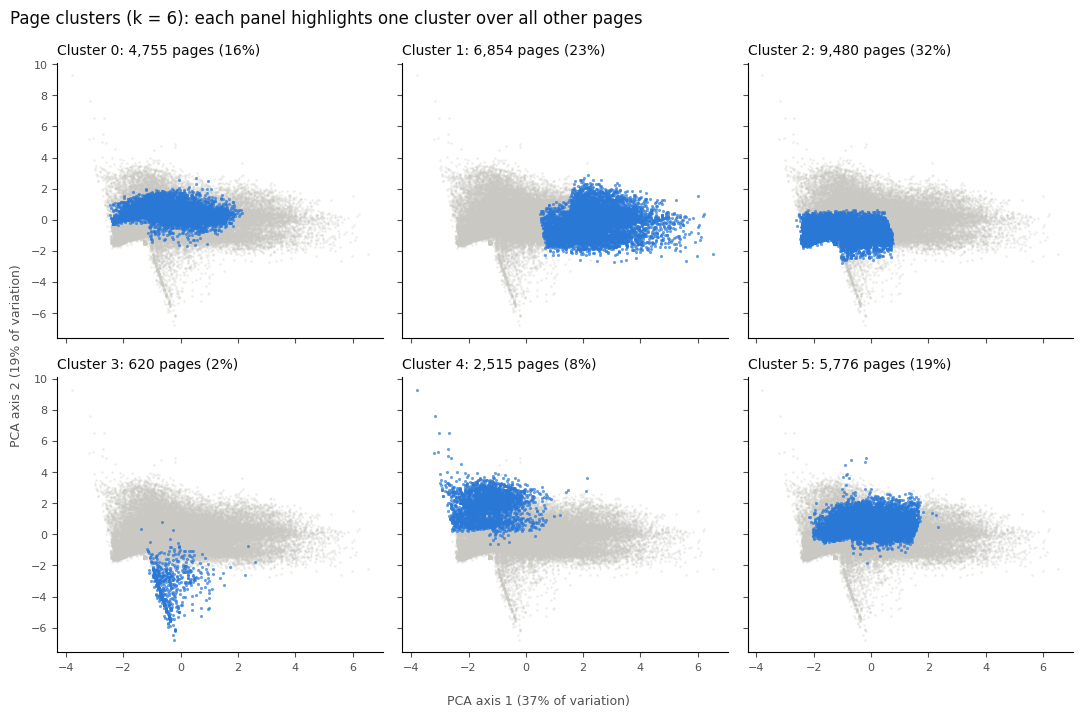

Note: this 2-D view keeps only 56% of the variation, so clusters that look overlapping here may be better separated in the full 7 metrics (and vice versa).

Cluster profiles (median of each metric):


,impressions_90d,clicks_90d,sessions_90d,ctr,avg_position,content_age_days,days_since_last_update,pages,share_trending_down
0,975.0,1.0,9.0,0.08,13.1,460.0,22.0,4755,0.48
1,9686.0,27.0,66.0,0.31,8.5,211.0,22.0,6854,0.56
2,83.5,0.0,3.0,0.00,8.0,138.0,20.0,9480,0.54
3,16.0,1.0,2.0,8.14,5.5,290.0,20.0,620,0.35
4,233.0,0.0,3.0,0.00,50.6,333.0,22.0,2515,0.38
5,748.0,1.0,8.0,0.03,12.8,263.0,104.0,5776,0.68


In [5]:
# --- Plot: where do the clusters sit? (2-D PCA view of the 7 scaled metrics) ---
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
xy = pca.fit_transform(Xs)
ev = pca.explained_variance_ratio_
labels = sketch["cluster"].to_numpy()

GREY, ACCENT, INK, MUTED = "#c9c8c2", "#2a78d6", "#0b0b0b", "#52514e"
ncols = 3
nrows = int(np.ceil(best_k / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(11, 3.6 * nrows), sharex=True, sharey=True)
for k, ax in zip(range(best_k), np.ravel(axes)):
    mask = labels == k
    ax.scatter(xy[~mask, 0], xy[~mask, 1], s=3, c=GREY, alpha=0.35, linewidths=0, rasterized=True)
    ax.scatter(xy[mask, 0], xy[mask, 1], s=5, c=ACCENT, alpha=0.7, linewidths=0, rasterized=True)
    ax.set_title(f"Cluster {k}: {mask.sum():,} pages ({mask.mean():.0%})", fontsize=10, color=INK, loc="left")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(labelsize=8, colors=MUTED)
for ax in np.ravel(axes)[best_k:]:
    ax.axis("off")
fig.supxlabel(f"PCA axis 1 ({ev[0]:.0%} of variation)", fontsize=9, color=MUTED)
fig.supylabel(f"PCA axis 2 ({ev[1]:.0%} of variation)", fontsize=9, color=MUTED)
fig.suptitle(f"Page clusters (k = {best_k}): each panel highlights one cluster over all other pages",
             fontsize=12, color=INK, x=0.02, ha="left")
fig.tight_layout()
plt.show()
print(f"Note: this 2-D view keeps only {ev.sum():.0%} of the variation, so clusters that look "
      "overlapping here may be better separated in the full 7 metrics (and vice versa).")

# --- Cluster profiles: typical values per cluster (median) ---
profile = pages[FEATURES].groupby(labels).median().round(2)
profile["pages"] = pd.Series(labels).value_counts().sort_index()
profile["share_trending_down"] = pages["trend_direction"].eq("down").groupby(labels).mean().round(2)
print("\nCluster profiles (median of each metric):")
display(profile)

## 5. Why ML beats a fixed rule here

*What makes the pattern too messy for an if-statement?*

*Write your answer in your own words here (a short paragraph). The cell below shows evidence from the data you can point to.*

In [6]:
# Evidence for Section 5: what a fixed rule does with this data
# Example rule from the course guide: "low-CTR visible page"
rule = ((pages["impressions_90d"] >= 500) & (pages["avg_position"] > 0)
        & (pages["avg_position"] <= 20) & (pages["ctr"] < 0.5))
print(f"Fixed rule 'low-CTR visible page' flags {rule.sum():,} pages ({rule.mean():.1%} of the inventory).")
print("\nInside that one flagged group, pages still differ a lot (25th / median / 75th percentile):")
print(pages.loc[rule, ["ctr", "avg_position", "engagement_rate", "sessions_90d", "content_age_days"]]
      .quantile([0.25, 0.5, 0.75]).round(2).to_string())
print("\nOne threshold lumps together pages that need different actions, "
      "and every new rule needs thresholds someone must choose by hand.")


Fixed rule 'low-CTR visible page' flags 9,759 pages (32.5% of the inventory).

Inside that one flagged group, pages still differ a lot (25th / median / 75th percentile):
       ctr  avg_position  engagement_rate  sessions_90d  content_age_days
0.25  0.08           5.9             0.00           7.0             131.0
0.50  0.17           8.4             0.00          18.0             236.0
0.75  0.28          12.7             3.57          44.0             389.0

One threshold lumps together pages that need different actions, and every new rule needs thresholds someone must choose by hand.


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.